# 05 · Modelo de comparación: LightGBM

**Objetivo:** entrenar un modelo de *machine learning* más complejo para responder una pregunta de negocio: **¿cuánto poder predictivo se pierde por usar un scorecard explicable?** Si la diferencia es pequeña, el scorecard es la mejor opción; si es grande, vale la pena considerar el modelo complejo o usarlo como apoyo.

## Conceptos

### Gradient boosting (LightGBM)

Construye cientos de **árboles de decisión** pequeños, uno tras otro. Cada árbol nuevo se enfoca en los clientes que los anteriores calificaron mal y corrige sus errores. La predicción final combina todos los árboles. Es como un comité de analistas donde cada uno aprende de los errores de los anteriores.

| | Scorecard (regresión logística) | LightGBM |
|---|---|---|
| Preparación | Requiere tramos y WoE | Usa los datos limpios directamente (maneja faltantes por sí solo) |
| Relaciones | Una por variable, sumadas | Captura combinaciones entre variables (interacciones) |
| Explicación | Total: puntos por tramo | Parcial: requiere herramientas extra (valores SHAP) |
| Uso típico | Originación de crédito regulada | Detección de fraude, cobranza, modelos de apoyo |

### Validación cruzada y parada temprana

Para elegir la configuración del modelo **no se usa la muestra de prueba** (eso sería fuga de información). En su lugar, la muestra de entrenamiento se divide en 5 partes: se entrena con 4 y se evalúa con la quinta, rotando 5 veces. Es como hacer 5 exámenes de práctica antes del examen final.

La **parada temprana** decide cuántos árboles usar: se dejan de agregar cuando el modelo deja de mejorar en la parte de validación. Así se evita el **sobreajuste**, que es memorizar los datos de entrenamiento en lugar de aprender patrones generales.

### AUC (adelanto de la etapa 6)

Para comparar configuraciones se usa el **AUC**: la probabilidad de que el modelo le asigne más riesgo a un cliente malo que a uno bueno, tomados al azar. 0.5 = adivinar con una moneda; 1 = separación perfecta. En la etapa 6 se explica a detalle junto con Gini y KS.

## Entorno

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "credit-risk-scorecard"
CARPETA_DRIVE = Path("/content/drive/MyDrive/credit-risk-scorecard")  # Donde está cs-training.csv

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/credit-risk-scorecard


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.comparacion import (
    buscar_hiperparametros,
    contribuciones_cliente,
    entrenar_lightgbm,
    graficar_importancia,
    importancia_variables,
)
from src.datos import copiar_datos_crudos
from src.limpieza import obtener_datos_limpios
from src.scorecard import construir_scorecard, desglose_cliente
from src.woe import VARIABLES_CANDIDATAS

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.float_format", "{:,.4f}".format)

In [4]:
copiar_datos_crudos(CARPETA_DRIVE)
train, test = obtener_datos_limpios()

Y = config.COLUMNA_OBJETIVO
X_train, y_train = train[VARIABLES_CANDIDATAS], train[Y]
X_test = test[VARIABLES_CANDIDATAS]

print(f"Variables ({len(VARIABLES_CANDIDATAS)}): las 10 candidatas, limpias y sin transformar a WoE")
print(f"Entrenamiento: {X_train.shape[0]:,} clientes | Prueba: {X_test.shape[0]:,} clientes")

Copiado cs-training.csv a data/raw/cs-training.csv
Variables (10): las 10 candidatas, limpias y sin transformar a WoE
Entrenamiento: 105,000 clientes | Prueba: 45,000 clientes


LightGBM recibe las **10 variables** limpias, incluidas las dos que la regresión logística descartó (ingreso y créditos abiertos): los árboles pueden encontrarles uso en combinación con otras variables. Los faltantes se dejan como están, porque LightGBM decide por sí mismo hacia qué lado del árbol enviarlos.

## 1. Búsqueda de hiperparámetros (validación cruzada en entrenamiento)

Se prueban 4 combinaciones de dos **hiperparámetros** (configuraciones que no se aprenden de los datos, sino que se eligen):
- `num_leaves`: qué tan complejo puede ser cada árbol.
- `min_child_samples`: mínimo de clientes en cada hoja del árbol. Igual que el tamaño mínimo de tramo en la etapa 3, evita reglas basadas en muy pocos clientes.

Esta celda tarda unos minutos.

In [5]:
busqueda = buscar_hiperparametros(X_train, y_train)
busqueda

,num_leaves,min_child_samples,n_arboles,auc_validacion,auc_desviacion
0,15,200,172,0.8661,0.0027
1,15,1000,137,0.8658,0.0029
2,31,1000,122,0.8655,0.0027
3,31,200,104,0.8651,0.0031


In [6]:
mejor = busqueda.iloc[0]
parametros = {"num_leaves": int(mejor["num_leaves"]), "min_child_samples": int(mejor["min_child_samples"])}
n_arboles = int(mejor["n_arboles"])

print(f"Mejor configuración: {parametros} con {n_arboles} árboles")
print(f"AUC de validación cruzada: {mejor['auc_validacion']:.4f} ± {mejor['auc_desviacion']:.4f}")

Mejor configuración: {'num_leaves': 15, 'min_child_samples': 200} con 172 árboles
AUC de validación cruzada: 0.8661 ± 0.0027


## 2. Modelo final

Se entrena con **todo** el conjunto de entrenamiento usando la mejor configuración. La muestra de prueba se sigue sin tocar: se usa en la etapa 6 para comparar ambos modelos en igualdad de condiciones.

In [7]:
modelo_lgb = entrenar_lightgbm(X_train, y_train, parametros, n_arboles)

pd_lgb_train = pd.Series(modelo_lgb.predict(X_train), index=train.index)
pd_lgb_test = pd.Series(modelo_lgb.predict(X_test), index=test.index)

pd.DataFrame({"entrenamiento": pd_lgb_train.describe(), "prueba": pd_lgb_test.describe()})

,entrenamiento,prueba
count,"105,000.0000","45,000.0000"
mean,0.0668,0.0663
std,0.1165,0.1156
min,0.0030,0.0032
25%,0.0095,0.0095
50%,0.0213,0.0213
75%,0.0645,0.0642
max,0.8783,0.8822


## 3. ¿Qué variables usa más?

La **importancia por ganancia** mide cuánto mejora el modelo gracias a cada variable, sumando todas las veces que se usa en los árboles.

,importancia_pct
variable,
atrasos_90,34.5526
uso_credito_revolvente,31.4845
atrasos_30_59,12.3162
atrasos_60_89,8.1548
razon_deuda,3.6762
edad,3.1087
ingreso_mensual,2.4769
num_creditos_abiertos,2.0952
num_creditos_inmobiliarios,1.7457


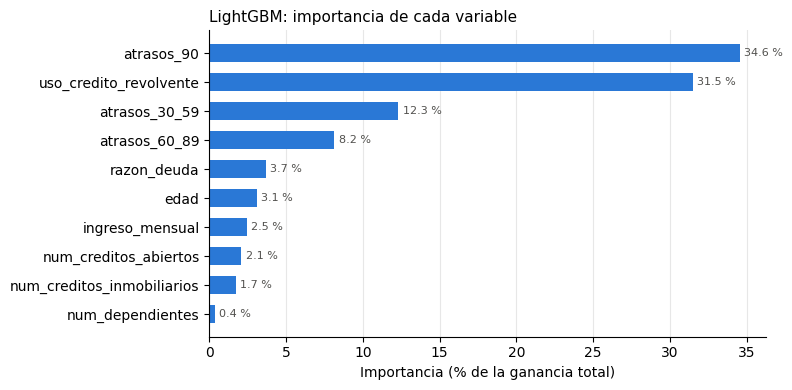

In [8]:
importancia = importancia_variables(modelo_lgb)
display(importancia)
graficar_importancia(importancia)
plt.show()

## 4. ¿Ordena a los clientes igual que el scorecard?

Sin usar todavía el resultado real de la muestra de prueba, se compara cómo ordenan a los clientes ambos modelos:
- **Correlación de Spearman** entre el puntaje del scorecard y la PD de LightGBM. Es negativa porque más puntos = menos riesgo; cerca de −1 = ordenan casi igual.
- **Coincidencia en el 10 % más riesgoso:** de los clientes que el scorecard pone en su peor 10 %, cuántos también están en el peor 10 % de LightGBM.

In [9]:
scorecard = construir_scorecard()
puntaje_test = scorecard["puntaje_test"]["puntaje"]

spearman = puntaje_test.corr(pd_lgb_test, method="spearman")

peor_scorecard = set(puntaje_test.nsmallest(int(len(test) * 0.10)).index)
peor_lgb = set(pd_lgb_test.nlargest(int(len(test) * 0.10)).index)
coincidencia = len(peor_scorecard & peor_lgb) / len(peor_scorecard)

print(f"Correlación de Spearman (puntaje vs. PD LightGBM): {spearman:.4f}")
print(f"Coincidencia en el 10 % más riesgoso: {coincidencia:.2%}")

Correlación de Spearman (puntaje vs. PD LightGBM): -0.9484
Coincidencia en el 10 % más riesgoso: 87.82%


## 5. Explicar la predicción de un cliente

Para el mismo cliente de la etapa 4 (el de menor puntaje en prueba) se comparan las dos explicaciones:
- **Scorecard:** puntos por variable (menos puntos = más riesgo).
- **LightGBM:** **valores SHAP**, la contribución de cada variable a la predicción, en logaritmo de momios (positivo = sube el riesgo).

La explicación del scorecard es directa y fija; la de LightGBM requiere un cálculo adicional y puede cambiar según la combinación de variables de cada cliente.

In [10]:
id_cliente = puntaje_test.idxmin()
print(f"Cliente {id_cliente} | Puntaje: {puntaje_test[id_cliente]} | PD LightGBM: {pd_lgb_test[id_cliente]:.2%}")

print("\nScorecard (puntos por variable):")
display(desglose_cliente(id_cliente, test, scorecard["agrupador"], scorecard["puntos"]).sort_values("puntos"))

print("LightGBM (contribución SHAP por variable):")
display(contribuciones_cliente(modelo_lgb, X_test, id_cliente))

Cliente 107427 | Puntaje: 414 | PD LightGBM: 78.22%

Scorecard (puntos por variable):


,valor,tramo,puntos
variable,,,
uso_credito_revolvente,1.0352,> 1.00,32
atrasos_90,3.0000,1+,35
atrasos_30_59,3.0000,3+,40
atrasos_60_89,1.0000,1+,47
razon_deuda,0.6513,0.61 – 0.72,60
edad,40.0000,37–41,66
num_creditos_inmobiliarios,0.0000,0,66
num_dependientes,3.0000,3,68


LightGBM (contribución SHAP por variable):


,valor,contribucion
variable,,
atrasos_90,3.0000,1.6730
uso_credito_revolvente,1.0352,1.1511
atrasos_30_59,3.0000,0.8924
atrasos_60_89,1.0000,0.6423
razon_deuda,0.6513,0.2120
num_dependientes,3.0000,0.0961
edad,40.0000,0.0739
num_creditos_inmobiliarios,0.0000,0.0498
ingreso_mensual,"1,800.0000",0.0430


## Hallazgos de la etapa

- **Mejor configuración:** árboles de 15 hojas, mínimo de 200 clientes por hoja y 172 árboles, con AUC de validación cruzada de 0.8661 ± 0.0027. Las cuatro configuraciones quedaron entre 0.8651 y 0.8661: el resultado casi no depende de los hiperparámetros, señal de un modelo robusto.
- **PD estimada:** promedio de 6.68 % en entrenamiento (igual a la tasa de malos real) y 6.63 % en prueba, con distribuciones casi idénticas en ambas muestras.
- **Variables más importantes:** atrasos de 90+ días (34.55 %), uso de crédito (31.48 %), atrasos de 30–59 días (12.32 %) y atrasos de 60–89 días (8.15 %) suman más del 86 % de la importancia. Son las mismas variables con mayor IV en el scorecard. Ingreso y créditos abiertos, que la regresión logística descartó, aportan poco aquí también (2.48 % y 2.10 %).
- **Coincidencia con el scorecard:** la correlación de Spearman entre el puntaje y la PD de LightGBM es de −0.9484, y el 87.82 % de los clientes que el scorecard pone en su peor 10 % también están en el peor 10 % de LightGBM. Ambos modelos ordenan el riesgo de forma muy parecida.
- **Explicación de un cliente:** para el cliente de menor puntaje (414 puntos), LightGBM estima una PD de 78.22 % y el scorecard de 92.65 %. Las razones principales coinciden en los dos modelos: 3 atrasos de 90+ días, uso de crédito mayor al 100 % y 3 atrasos de 30–59 días. La diferencia es que el scorecard lo explica con su tabla de puntos fija, mientras que LightGBM necesita un cálculo adicional (SHAP).

## Resumen de la etapa

- Se entrenó un modelo LightGBM con las 10 variables limpias, eligiendo su configuración con validación cruzada de 5 partes **solo en entrenamiento**.
- Se revisaron las variables más importantes, cuánto coincide con el scorecard al ordenar clientes y cómo explica la predicción de un cliente.
- `construir_modelo_comparacion()` en `src/comparacion.py` reconstruye el modelo de forma determinista para la etapa 6.

**Siguiente paso:** notebook `06_metricas.ipynb`, comparación formal de ambos modelos en la muestra de prueba con AUC, Gini y KS.